In [1]:
# 5 - Simple smoke tests
assert df.shape[0] >= 3
assert (Path('artifacts/wandb_dashboard_multi.png')).exists()
print('Visuals smoke tests passed')

# 6 - Optional: Auto-upload artifacts to W&B (defensive)
try:
    from scripts.benchmarks.continue_testing.examples import upload_artifacts_to_wandb

    # The call below will attempt to upload to W&B if available. Pass a wandb_module
    # when testing locally to avoid depending on a global installation.
    res = upload_artifacts_to_wandb({"csv": str(res['csv']), "plots": res['plots']}, project="org/example", run_name="example_run")
    print('W&B upload result:', res)
except Exception as e:
    print('Skipping W&B upload (wandb may be unavailable):', e)


NameError: name 'df' is not defined

NameError: name 'df' is not defined

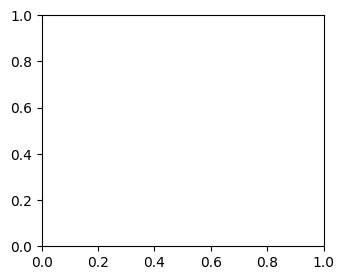

In [2]:
# 4 - Visualization (seaborn): per-run p50 and avg_cpu
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
sns.barplot(data=df, x='name', y='avg_cpu', palette='magma')
plt.title('Per-run avg_cpu')
plt.xticks(rotation=45)

plt.subplot(1,2,2)
sns.barplot(data=df, x='name', y='p50', palette='viridis')
plt.title('Per-run p50 (ms)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('artifacts/wandb_dashboard_multi.png', dpi=150)
plt.show()


# Optional: Authenticate to Weights & Biases (W&B)

This optional cell shows how to authenticate in a notebook environment. It is safe to skip — the upload helper also accepts a provided `wandb_module` for offline testing.

**Notes:**
- Preferred: set `WANDB_API_KEY` as an environment variable or run `wandb login` in your shell.
- Avoid embedding tokens directly in notebooks. Use environment variables or secrets management in CI.


In [3]:
# Optional authentication snippet (defensive)
import os
try:
    import wandb  # type: ignore
    token = os.environ.get("WANDB_API_KEY")
    if not token:
        print("WANDB_API_KEY not found. You can run `wandb login` or set the WANDB_API_KEY env var.")
        print("Skipping automatic login; upload helper can accept a wandb_module for offline testing.")
    else:
        try:
            # login with token (non-interactive)
            wandb.login(key=token)
            print("Successfully logged in to W&B (non-interactive via WANDB_API_KEY).")
        except Exception as e:
            print("wandb.login failed:", e)
            print("You can also run `wandb login` interactively in a terminal.")

    # Example of setting defaults (commented — run only when you want to start a real run):
    # run = wandb.init(project='org/example', name='example_run')
    # upload_artifacts_to_wandb({'csv': str(res['csv']), 'plots': res['plots']}, project='org/example', run_name='example_run')

except Exception as e:
    print('wandb is not installed or cannot be imported; to enable uploads install via `pip install wandb`')


WANDB_API_KEY not found. You can run `wandb login` or set the WANDB_API_KEY env var.
Skipping automatic login; upload helper can accept a wandb_module for offline testing.


In [4]:
# Programmatic upload example using the helper
from scripts.benchmarks.continue_testing.examples import upload_artifacts_to_wandb
import wandb
# Initialize a W&B run (will prompt for login if needed)
run = wandb.init(project='org/example', name='example_run')
# Call the upload helper; adjust paths as needed
res = upload_artifacts_to_wandb(
    {'csv': 'artifacts/wandb_dashboard_multi.csv', 'plots': ['artifacts/wandb_dashboard_multi.png']},
    project='org/example',
    run_name='example_run',
    wandb_module=wandb
)
print('Upload result:', res)
run.finish()

UsageError: Invalid project name 'org/example': cannot contain characters '/,\\,#,?,%,:', found '/'

In [5]:
# 3 - Load generated CSV to a DataFrame and show
import pandas as pd
from pathlib import Path

csv_path = Path(res['csv'])
df = pd.read_csv(csv_path)
print(df)


NameError: name 'res' is not defined

In [6]:
# 2 - Generate dashboard artifacts (offline, using fake wandb.Api)
from scripts.benchmarks.continue_testing.examples import generate_dashboard
from types import SimpleNamespace

# Fake Api for offline demo
class FakeApi:
    def runs(self, project=None):
        return [
            SimpleNamespace(name="run-A", summary={"avg_cpu": 12.5, "p50": 120}),
            SimpleNamespace(name="run-B", summary={"avg_cpu": 16.3, "p50": 110}),
            SimpleNamespace(name="run-C", summary={"avg_cpu": 9.1, "p50": 150}),
        ]

fake_wandb = SimpleNamespace(Api=lambda: FakeApi())

res = generate_dashboard("org/example", out_dir="artifacts", wandb_module=fake_wandb)
print('Artifacts:', res)


Artifacts: {'csv': 'artifacts\\org_example_per_run.csv', 'plots': {'bar': 'artifacts\\org_example_per_run_avg_cpu.png', 'aggregates': 'artifacts\\org_example_aggregates.png'}, 'aggregates': {'avg_cpu': 12.633333333333333, 'p50': 126.66666666666667}}


C:\Users\tomwo\git\lemonade\scripts\benchmarks\continue-testing\examples\wandb_dashboard_example.py:121: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="name", y=col, palette="viridis")


In [7]:
# 1 - Imports & versions
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Python', platform.python_version())
print('numpy', np.__version__)
print('pandas', pd.__version__)
print('seaborn', sns.__version__)


Python 3.13.9
numpy 2.4.0
pandas 2.3.3
seaborn 0.13.2


# W&B Dashboard Visuals Example
This notebook demonstrates generating dashboard artifacts (CSV + PNG) from W&B runs
using the `generate_dashboard` helper in the examples module. It is designed to
go beyond the simple example and show seaborn-based visuals that can be exported
for use in reports or dashboards.